# 05 — Architecture and training pipeline

**Scope.** How the model that produced the frozen aggregates is built and
trained: the feature contract, the split and embargo arithmetic, the
matched-vintage warm comparators, the estimator and calibration, and the V2
A0–A7 audit arms. The pipeline is displayed from the shipped aggregates and
re-run only on **synthetic arrays**; the real ICEWS v37 panel is restricted and
is **not** redistributed, so no real fit happens here.

**Status.** V1 (holdout) is the plan-declared primary of record; V2 is a
**post-hoc secondary** matched-vintage audit on a burned holdout. The synthetic
demo is a teaching device: it shows the mechanics, not a paper number.


In [1]:
from pathlib import Path
import json
import sys

import numpy as np
import pandas as pd

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)

try:
    from IPython.display import display
except Exception:
    display = print


def find_repo_root() -> Path:
    here = Path.cwd().resolve()
    for cand in (here, *here.parents):
        if (cand / "results" / "framework_pilot").is_dir():
            return cand
    return here


ROOT = find_repo_root()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

V2 = ROOT / "results" / "framework_pilot_v2"
V2T = V2 / "tables"


def rel(path: Path) -> str:
    try:
        return str(Path(path).relative_to(ROOT))
    except ValueError:
        return str(path)


def load_csv(path: Path) -> pd.DataFrame:
    if not path.is_file():
        print(f"[missing] {rel(path)}")
        return pd.DataFrame()
    return pd.read_csv(path)


def load_json(path: Path) -> dict:
    if not path.is_file():
        print(f"[missing] {rel(path)}")
        return {}
    with path.open(encoding="utf-8") as fh:
        return json.load(fh)


MORANDI = {
    "slate": "#35525F",
    "terracotta": "#A2664F",
    "sage": "#84957A",
    "ochre": "#C2A05F",
    "brick": "#8C5A52",
    "ink": "#33383B",
    "grey": "#8B8883",
    "sand": "#E6DED2",
}

def show_figure(fig) -> None:
    # Render as an embedded PNG: the executor runs without an inline backend.
    try:
        import io
        from IPython.display import Image, display as show
        buffer = io.BytesIO()
        fig.savefig(buffer, format="png", dpi=150, bbox_inches="tight")
        show(Image(data=buffer.getvalue()))
    except Exception as exc:
        print(f"[figure not rendered] {exc}")


print("repo root:", rel(ROOT))
print("numpy", np.__version__, "| pandas", pd.__version__)
print("V2 aggregate tree:", "present" if V2.is_dir() else "MISSING")


repo root: .
numpy 2.5.4 | pandas 2.3.3
V2 aggregate tree: present


## 1. Feature contract: 27 + 20 + 2

| Block | Columns | Count | Available at scoring time |
|---|---|---|---|
| Dyad-causal | lagged/current event counts, rates, recency, ego counts | 27 | yes |
| Graph core | 5 undirected terms × source/target, 5 neighbour-activity terms, 2 ego counts per role | 20 | yes |
| Train-only | `br` (base rate), `seen_tr` (seen-in-training flag) | 2 | constant on evaluation |

The four shipped specifications are nested subsets:

- **49** = 27 + 20 + 2 — the plan-declared V1 specification;
- **47** = 49 − {`br`, `seen_tr`} — the V2 primary (removes the two columns
  that are constant on the evaluation window);
- **29** = 27 + 2 — the plan-declared V1 secondary;
- **25** = 27 − {`src_ev`, `tgt_ev`} — the V2 key secondary, with no actor-owned
  column at all (a floor on what the actor block can buy).

The next cell rebuilds the four sets from `framework/features.py` and checks the
arithmetic against the paper, without reading any data.


In [2]:
from framework import features as F

DYAD = list(F.DYAD_CAUSAL)
GRAPH = list(F.GRAPH_CORE20)
F49 = DYAD + GRAPH + ["br", "seen_tr"]
F47 = [c for c in F49 if c not in ("br", "seen_tr")]
F29 = DYAD + ["br", "seen_tr"]
F25 = [c for c in DYAD if c not in ("src_ev", "tgt_ev")]

block = pd.DataFrame(
    [("dyad-causal", len(DYAD), 27, "27 == len(DYAD_CAUSAL)"),
     ("graph core", len(GRAPH), 20, "20 == len(GRAPH_CORE20)"),
     ("train-only", 2, 2, "br + seen_tr"),
     ("49 = 27+20+2", len(F49), 49, "plan-declared V1 primary"),
     ("47 = 49-2", len(F47), 47, "V2 primary"),
     ("29 = 27+2", len(F29), 29, "plan-declared V1 secondary"),
     ("25 = 27-2", len(F25), 25, "V2 key secondary")],
    columns=["block", "count", "expected", "role"],
)
display(block)
checks = (len(DYAD), len(GRAPH), len(F49), len(F47), len(F29), len(F25))
print("counts:", checks, "| match:", checks == (27, 20, 49, 47, 29, 25))
print("47 is 49 minus train-only columns:",
      set(F47) == set(F49) - {"br", "seen_tr"})
print("25 is the dyad block minus the two ego counts:",
      set(F25) == set(DYAD) - {"src_ev", "tgt_ev"})


,block,count,expected,role
0,dyad-causal,27,27,27 == len(DYAD_CAUSAL)
1,graph core,20,20,20 == len(GRAPH_CORE20)
2,train-only,2,2,br + seen_tr
3,49 = 27+20+2,49,49,plan-declared V1 primary
4,47 = 49-2,47,47,V2 primary
5,29 = 27+2,29,29,plan-declared V1 secondary
6,25 = 27-2,25,25,V2 key secondary


counts: (27, 20, 49, 47, 29, 25) | match: True
47 is 49 minus train-only columns: True
25 is the dyad block minus the two ego counts: True


## 2. Split, embargo and windows

Month index 0 = 1995-01. The frozen plan fixes the windows below; every row
count in the aggregates is the **filtered** panel (holdout dyads and embargo
months removed), not the raw panel count.

| Window | Months | Role |
|---|---|---|
| train | 0–238 | fitting only |
| embargo | 239, 251, 275, 335 | dropped from every window |
| select | 240–250 | hyper-parameter choice (selection only) |
| inner validation | 252–274 | post-hoc period views (A8 inner) |
| evaluation (holdout) | 276–334 | burned 2018-01…2022-11 |
| extended (A6) | 0–274 | vintage-sensitivity training window |

The holdout is **unit-fresh** (5,282 directed dyads, 2,790 unordered pairs) but
**not time-fresh**: 2018–22 was burned by earlier exploratory passes, so every
V2 number is post-hoc.


In [3]:
summary = load_json(V2 / "summary.json")
counts = summary.get("row_counts", {}) if summary else {}
warm = load_csv(V2T / "warm_support.csv")

windows = pd.DataFrame(
    [("train", "0-238", "fit"), ("embargo", "239, 251, 275, 335", "dropped"),
     ("select", "240-250", "C fixed at 1.0; selection only"),
     ("inner", "252-274", "A8 inner-period shares"),
     ("evaluation", "276-334", "burned unit-fresh holdout"),
     ("extended (A6)", "0-274", "vintage sensitivity")],
    columns=["window", "t_idx", "role"],
)
display(windows)

positives = None
arms_pos = load_csv(V2T / "arms_main.csv")
if not arms_pos.empty:
    positives = int(arms_pos["positives"].iloc[0])

if counts:
    rows = pd.DataFrame(
        [("train rows", counts.get("tr")),
         ("selection rows", counts.get("sel")),
         ("evaluation rows", counts.get("ev")),
         ("evaluation positives", positives),
         ("inner rows", counts.get("inn")),
         ("extended rows", counts.get("ext"))],
        columns=["filtered count", "rows"],
    )
    display(rows.astype({"rows": "Int64"}))
if not warm.empty:
    display(warm[["cutoff", "eval_rows", "rows_n0", "markov_at_global"]])
print("filtered panel: 5,055,328 train / 232,672 select / 311,638 eval "
      "(32,614 positives) / 5,816,800 extended")


,window,t_idx,role
0,train,0-238,fit
1,embargo,"239, 251, 275, 335",dropped
2,select,240-250,C fixed at 1.0; selection only
3,inner,252-274,A8 inner-period shares
4,evaluation,276-334,burned unit-fresh holdout
5,extended (A6),0-274,vintage sensitivity


,filtered count,rows
0,train rows,5055328
1,selection rows,232672
2,evaluation rows,311638
3,evaluation positives,32614
4,inner rows,607982
5,extended rows,5816800


,cutoff,eval_rows,rows_n0,markov_at_global
0,239,311638,0,706
1,275,311638,0,329


filtered panel: 5,055,328 train / 232,672 select / 311,638 eval (32,614 positives) / 5,816,800 extended


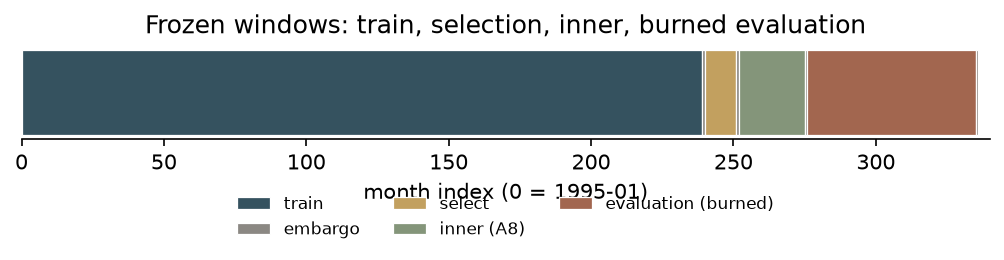

In [4]:
import matplotlib.pyplot as plt

spans = [("train", 0, 238, MORANDI["slate"]),
         ("embargo", 239, 239, MORANDI["grey"]),
         ("select", 240, 250, MORANDI["ochre"]),
         ("embargo", 251, 251, MORANDI["grey"]),
         ("inner (A8)", 252, 274, MORANDI["sage"]),
         ("embargo", 275, 275, MORANDI["grey"]),
         ("evaluation (burned)", 276, 334, MORANDI["terracotta"]),
         ("embargo", 335, 335, MORANDI["grey"])]

fig, ax = plt.subplots(figsize=(6.8, 2.4))
seen = set()
for label, lo, hi, colour in spans:
    ax.barh(0, hi - lo + 1, left=lo, height=0.5, color=colour,
            edgecolor="white", linewidth=0.6,
            label=label if label not in seen else None)
    seen.add(label)
ax.set_yticks([])
ax.set_xlim(0, 340)
ax.set_xlabel("month index (0 = 1995-01)")
ax.set_title("Frozen windows: train, selection, inner, burned evaluation")
ax.legend(frameon=False, ncol=3, fontsize=8, loc="upper center",
          bbox_to_anchor=(0.5, -0.45))
for spine in ("top", "right", "left"):
    ax.spines[spine].set_visible(False)
fig.tight_layout()
show_figure(fig)


## 3. Warm comparators: original vs matched vintage

The comparison that matters is not "model vs per-dyad Markov" (that baseline
collapses to the global transition on unit-fresh dyads) but "model vs the same
warm-history baseline the earlier round used". The earlier round used counts
observed through month **275** — i.e. it peeked at the evaluation window. V2 adds
a **matched-vintage** comparator that stops at month **239**, the same cutoff the
model sees.

Both comparators share the same estimator form: a per-dyad Markov step
conditional on current activity plus a smoothed per-dyad rate, with a
Beta(1,1)-style prior and the global transition/rate as the fallback. The
only difference is the cutoff. The synthetic demo below shows what that single
choice does, using invented counts only.


In [5]:
rng = np.random.default_rng(20261023)

# SYNTHETIC: 400 dyads, 60 months, no ICEWS content whatsoever.
n_dyads, n_months = 400, 60
active = np.zeros((n_dyads, n_months), dtype=np.int8)
active[:, 0] = rng.integers(0, 2, n_dyads)
for t in range(1, n_months):
    p_on = np.where(active[:, t - 1] == 1, 0.62, 0.04)
    active[:, t] = rng.binomial(1, p_on)
nxt = np.zeros_like(active)
nxt[:, :-1] = active[:, 1:]

def warm_counts(panel, nxt, cutoff):
    a, y = panel[:, :cutoff], nxt[:, :cutoff]
    out = {"n": np.full(a.shape[0], a.shape[1]), "n1": a.sum(1),
           "n0": (1 - a).sum(1)}
    out["k"] = y.sum(1)
    out["n11"] = (a * y).sum(1)
    out["n01"] = ((1 - a) * y).sum(1)
    g = float(y.mean())
    pg1 = float(((a == 1) * y).sum() / max((a == 1).sum(), 1))
    pg0 = float(((a == 0) * y).sum() / max((a == 0).sum(), 1))
    return out, g, pg1, pg0

def warm_predict(counts, did, active_now, g, pg1, pg0):
    # Per-row prediction for the rows of `did`; same form as the V2 runner.
    markov = np.where(
        active_now == 1,
        (counts["n11"][did] + 2.0 * pg1) / (counts["n1"][did] + 2.0),
        (counts["n01"][did] + 2.0 * pg0) / (counts["n0"][did] + 2.0))
    rate = (counts["k"][did] + 2.0 * g) / (counts["n"][did] + 2.0)
    return markov, rate

def log_loss(y, p):
    p = np.clip(np.asarray(p, float), 1e-12, 1 - 1e-12)
    return float(-np.mean(y * np.log(p) + (1 - y) * np.log(1 - p)))

eval_lo = 40
horizon = n_months - eval_lo
y_eval = nxt[:, eval_lo:].ravel()
a_eval = active[:, eval_lo:].ravel()
did_eval = np.repeat(np.arange(n_dyads), horizon)
rows = []
for label, cutoff in (("matched vintage (train end)", 40),
                      ("original vintage (train + eval peek)", 60)):
    counts, g, pg1, pg0 = warm_counts(active, nxt, cutoff)
    markov, rate = warm_predict(counts, did_eval, a_eval, g, pg1, pg0)
    rows.append((label, cutoff, log_loss(y_eval, markov),
                 log_loss(y_eval, rate)))
demo = pd.DataFrame(rows, columns=["comparator", "count cutoff (month)",
                                   "Markov log-loss", "rate log-loss"])
display(demo.round(6))
print("SYNTHETIC demo: the original-vintage comparator sees the evaluation "
      "months, so its lower loss is an artefact of the cutoff, not of skill")


,comparator,count cutoff (month),Markov log-loss,rate log-loss
0,matched vintage (train end),40,0.234184,0.341073
1,original vintage (train + eval peek),60,0.197914,0.275726


SYNTHETIC demo: the original-vintage comparator sees the evaluation months, so its lower loss is an artefact of the cutoff, not of skill


## 4. Estimator and calibration

- **Estimator.** Standardised L2 logistic regression, `C = 1.0` fixed for every
  V2 arm except the D1 reconciliation (`C = 0.3`, `T = 1.1`), `lbfgs`,
  `max_iter = 300`, no class weighting. Coefficients are the explanation.
- **Standardisation.** `mu`/`s` are fitted on the training window only and
  stored beside the fit; contributions are `w_j (x_j − mu_j)/s_j`.
- **Calibration.** V1 selected among none / temperature / isotonic on the
  selection window. V2 holds calibration fixed at `T = 1.0` for every arm so
  that contrasts isolate the feature/cache change; only D1 carries a
  temperature.
- **No tuning on evaluation.** `C` never sees 276–334; the selection window
  (240–250) is used only where a hyper-parameter is chosen at all.

The demo below runs the shipped estimator (`framework.models.fit_logistic`) on
synthetic arrays and shows the temperature transform from `framework.models`.


In [6]:
from framework.config import load_config
from framework import models
from framework.metrics import binary_metrics

cfg = load_config(overrides={"models": {"logistic": {"max_iter": 300}}})
rs = np.random.default_rng(7)
n = 4000
X_syn = rs.normal(size=(n, 5))
beta = np.array([1.1, -0.8, 0.5, 0.0, 0.3])
logit = -2.2 + X_syn @ beta
y_syn = rs.binomial(1, 1 / (1 + np.exp(-logit)))
cut = 3000

fit = models.fit_logistic(X_syn[:cut], y_syn[:cut], X_syn[cut:], y_syn[cut:],
                          cfg, C_grid=[1.0], feature_names=[f"f{j}" for j in range(5)])
p_raw = models.predict_logistic(fit, X_syn[cut:])
p_T = models.apply_temperature(p_raw, 1.4)
m_raw = binary_metrics(y_syn[cut:], p_raw)
m_T = binary_metrics(y_syn[cut:], p_T)

display(pd.DataFrame({"feature": fit["feature_names"],
                      "standardised coef": np.round(fit["coef"], 4)}))
display(pd.DataFrame(
    [("C", fit["C"]), ("select log-loss", round(fit["select_log_loss"], 6)),
     ("eval log-loss, T=1.0", round(m_raw["log_loss"], 6)),
     ("eval log-loss, T=1.4", round(m_T["log_loss"], 6)),
     ("eval ECE, T=1.0", round(m_raw["ece"], 6)),
     ("eval ECE, T=1.4", round(m_T["ece"], 6))],
    columns=["quantity", "SYNTHETIC value"]))
print("temperature is a one-parameter affine map on the logit; it cannot "
      "change ranking (AUC), only calibration and the intercept")


,feature,standardised coef
0,f0,1.0407
1,f1,-0.7769
2,f2,0.5094
3,f3,-0.0511
4,f4,0.3171


,quantity,SYNTHETIC value
0,C,1.000000
1,select log-loss,0.365074
2,"eval log-loss, T=1.0",0.365074
3,"eval log-loss, T=1.4",0.379447
4,"eval ECE, T=1.0",0.013155
5,"eval ECE, T=1.4",0.061724


temperature is a one-parameter affine map on the logit; it cannot change ranking (AUC), only calibration and the intercept


In [7]:
# Exact additive decomposition of the synthetic fit (same identity as notebook 04).
from framework import aggregation as A

contrib = A.contributions(fit, X_syn[cut:])
report = A.exactness_report(fit, contrib, p_raw)
print(f"synthetic rows: {report['n_rows']}")
print(f"max |b + sum c - logit p| = {report['raw_max_abs_error']:.3e}")
print(f"rows above 1e-5: {report['raw_rows_above_tol']}")
print("the identity holds row by row; it is the estimator's algebra, not a "
      "claim about the data")


synthetic rows: 1000
max |b + sum c - logit p| = 5.738e-07
rows above 1e-5: 0
the identity holds row by row; it is the estimator's algebra, not a claim about the data


## 5. V2 audit arms A0–A7

| Arm | Fit | Features | Cache | Baseline | Question |
|---|---|---|---|---|---|
| A0 | F1 | 49 | H0 | original-vintage warm | does the V1 replication hold? |
| A1 | F2 | 49 | P1 | matched-vintage warm | as-specified model on the fixed cache |
| A2 | F3 | 47 | P1 | matched-vintage warm | **primary** (drop `br`, `seen_tr`) |
| A3 | F3 | 47 | P1 | original-vintage warm | both comparators |
| A4 | F4 | 29 | P1 | matched-vintage warm | V1 secondary specification |
| A5 | F5 | 25 | P1 | matched-vintage warm | no actor-owned column |
| A6 | F6/F7 | 49/47 | P1 | original-vintage warm | extended 0–274 training window |
| A7 | F1/F8/F9 | 49/47/25 | H0 | matched/original warm | the cache factor |
| nested | F3 vs F5 | 47 vs 25 | P1 | — | do the 22 added columns buy anything? |

`H0` is the holdout-zeroed graph cache (V1's rule); `P1` is the as-specified
cache. The cache factor is paired within feature set, so it isolates the cache
from the feature change.


In [8]:
arms = load_csv(V2T / "arms_main.csv")
contr = load_csv(V2T / "arms_contrasts.csv")

if not arms.empty:
    keep = ["predictor", "kind", "features", "cache", "C", "T", "arm",
            "log_loss", "brier", "ece", "auc", "ap"]
    display(arms[keep].round(4).reset_index(drop=True))
    fits = arms[arms["kind"] == "fit"]
    warm_rows = arms[arms["kind"] == "warm"]
    print("rows:", len(arms), "=", len(fits), "fits +", len(warm_rows),
          "warm comparators")
    print("feature sets:", [int(v) for v in sorted(fits["features"].unique())])
    fixed = fits[fits["predictor"] != "D1"]
    print("every V2 fit except D1 uses C=1.0 and T=1.0:",
          bool((fixed["C"] == 1.0).all() and (fixed["T"] == 1.0).all()))
    print("D1 (reconciliation only): C=0.3, T=1.1")
else:
    print("No arms table; the arm display is unavailable.")


,predictor,kind,features,cache,C,T,arm,log_loss,brier,ece,auc,ap
0,F1,fit,49.0,H0,1.0,1.0,A0/A7,0.2180,0.0641,0.0422,0.9102,0.6717
1,F2,fit,49.0,P1,1.0,1.0,A1,0.2032,0.0586,0.0247,0.9097,0.6705
2,F3,fit,47.0,P1,1.0,1.0,A2/A3,0.1939,0.0552,0.0089,0.9103,0.6755
3,F4,fit,29.0,P1,1.0,1.0,A4,0.2050,0.0593,0.0241,0.9083,0.6717
4,F5,fit,25.0,P1,1.0,1.0,A5,0.1971,0.0558,0.0125,0.9067,0.6709
5,F6,fit,49.0,P1,1.0,1.0,A6,0.2029,0.0587,0.0240,0.9100,0.6718
6,F7,fit,47.0,P1,1.0,1.0,A6,0.1932,0.0550,0.0040,0.9104,0.6758
7,F8,fit,47.0,H0,1.0,1.0,A7,0.1938,0.0552,0.0086,0.9103,0.6757
8,F9,fit,25.0,H0,1.0,1.0,A7,0.1971,0.0558,0.0125,0.9067,0.6709
9,D1,fit,29.0,H0,0.3,1.1,D-2 diagnostic,0.2052,0.0590,0.0275,0.9083,0.6717


rows: 14 = 10 fits + 4 warm comparators
feature sets: [25, 29, 47, 49]
every V2 fit except D1 uses C=1.0 and T=1.0: True
D1 (reconciliation only): C=0.3, T=1.1


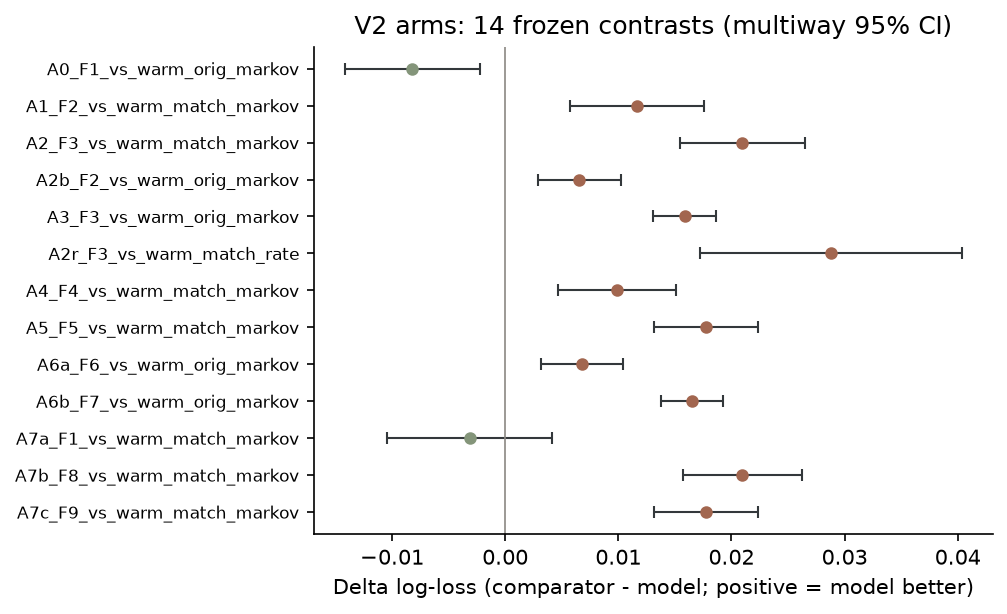

In [9]:
if not contr.empty:
    plot = contr[contr["contrast"] != "NESTED_F5_base_vs_F3_model"].copy()
    plot = plot.iloc[::-1].reset_index(drop=True)
    fig, ax = plt.subplots(figsize=(6.8, 4.2))
    for i, row in plot.iterrows():
        d = float(row["d_log_loss"])
        lo, hi = float(row["ll_ci_lo"]), float(row["ll_ci_hi"])
        colour = MORANDI["terracotta"] if d > 0 else MORANDI["sage"]
        ax.errorbar([d], [i], xerr=[[d - lo], [hi - d]], fmt="o",
                    color=colour, ecolor=MORANDI["ink"], elinewidth=1.0,
                    capsize=3, markersize=5)
    ax.axvline(0, color=MORANDI["grey"], linewidth=0.8)
    ax.set_yticks(range(len(plot)))
    ax.set_yticklabels(plot["contrast"], fontsize=8)
    ax.set_xlabel("Delta log-loss (comparator - model; positive = model better)")
    ax.set_title("V2 arms: 14 frozen contrasts (multiway 95% CI)")
    for spine in ("top", "right"):
        ax.spines["top"].set_visible(False)
        ax.spines["right"].set_visible(False)
    fig.tight_layout()
    show_figure(fig)
else:
    print("No contrast table; the forest is unavailable.")


## 6. Cache factor and A0/A7 reconciliation

`a7_cache_matrix.csv` pairs the same feature set across the two graph caches
(`dll = H0 − P1`, positive means the as-specified cache is better), and
`reconciliation.csv` compares the V2 rerun with the frozen V1 anchors. A
`STOP` in that table would have aborted the V2 report; the frozen statuses are
`PASS` / `PASS_WITH_NOTE` only.


In [10]:
cache = load_csv(V2T / "a7_cache_matrix.csv")
recon = load_csv(V2T / "reconciliation.csv")

if not cache.empty:
    display(cache[["features", "cache", "fit", "ll_model",
                   "dll_vs_orig", "dll_vs_match"]].round(6))
if not recon.empty:
    display(recon[["arm", "quantity", "observed", "expected", "delta",
                   "status"]].round(8))
    statuses = {str(k): int(v) for k, v in recon["status"].value_counts().items()}
    print("reconciliation statuses:", statuses)
    print("no STOP row:", bool(not recon["status"].eq("STOP").any()))


,features,cache,fit,ll_model,dll_vs_orig,dll_vs_match
0,49,P1,F2,0.203181,0.006548,0.011640
1,49,H0,F1,0.217964,-0.008235,-0.003143
2,47,P1,F3,0.193867,0.015862,0.020954
3,47,H0,F8,0.193850,0.015879,0.020971
4,25,P1,F5,0.197078,0.012651,0.017743
5,25,H0,F9,0.197078,0.012651,0.017743


,arm,quantity,observed,expected,delta,status
0,A0,F1 log_loss,0.217964,0.217875,0.000089,PASS_WITH_NOTE
1,A0,warm_orig_markov log_loss,0.209729,0.209729,0.000000,PASS
2,A7,F8 log_loss,0.193850,0.193850,0.000000,PASS
3,A7,F9 log_loss,0.197078,0.197023,0.000055,PASS_WITH_NOTE
4,A0,warm_orig_rate log_loss,0.214682,0.214682,0.000000,PASS
5,D1,"D1 log_loss (C=0.3,T=1.1)",0.205219,0.205219,0.000000,PASS
6,A7,warm_orig_markov - F8 (gain),0.015879,0.015879,0.000000,PASS


reconciliation statuses: {'PASS': 5, 'PASS_WITH_NOTE': 2}
no STOP row: True


## 7. Why this notebook cannot train the paper model

- The **ICEWS v37 event panel** (doi:10.7910/DVN/28075) and the derived
  feature/graph caches are licensed and are **not redistributed**; the public
  tree ships no cache-build driver.
- The V2 runner (`experiments/sprint_c_v2.py`) is shipped for audit but fails
  closed: it needs the licensed panel, the restricted caches and the frozen
  protocol, and its compare/A8/A9 stages need row-level predictions that are
  withheld.
- The frozen aggregates and their `SHA256SUMS` are the reproducible unit. The
  notebook therefore *displays* the pipeline and *demonstrates* the mechanics
  on synthetic arrays.
- Nothing here is a paper figure. `paper/` is not redistributed; the paper is
  cited by its arXiv link only.


In [11]:
rows = [
    ("feature blocks", "27 dyad-causal + 20 graph + 2 train-only"),
    ("specifications", "49 / 47 / 29 / 25"),
    ("estimator", "standardised L2 logistic, C=1.0, T=1.0 (D1: C=0.3, T=1.1)"),
    ("evaluation", "5,282 directed holdout dyads, 311,638 dyad-months, burned"),
    ("comparators", "matched-vintage (cutoff 239) vs original (cutoff 275)"),
    ("caches", "P1 as-specified vs H0 holdout-zeroed"),
    ("audit arms", "A0-A7 plus the nested 47-vs-25 contrast"),
    ("synthetic demo", "mechanics only - not a paper number"),
]
display(pd.DataFrame(rows, columns=["component", "value"]))
print("status: pipeline displayed from aggregates; real ICEWS restricted; "
      "V2 post hoc secondary")


,component,value
0,feature blocks,27 dyad-causal + 20 graph + 2 train-only
1,specifications,49 / 47 / 29 / 25
2,estimator,"standardised L2 logistic, C=1.0, T=1.0 (D1: C=..."
3,evaluation,"5,282 directed holdout dyads, 311,638 dyad-mon..."
4,comparators,matched-vintage (cutoff 239) vs original (cuto...
5,caches,P1 as-specified vs H0 holdout-zeroed
6,audit arms,A0-A7 plus the nested 47-vs-25 contrast
7,synthetic demo,mechanics only - not a paper number


status: pipeline displayed from aggregates; real ICEWS restricted; V2 post hoc secondary
